# Extension — Decision Tree, Random Forest & Gradient Boosting vs Logistic Regression

**Prediction point: the day before arrival** (same as Notebook 04). Same features and same train/test split as `04_classification.ipynb`, so the comparison is fair.

**Why?** Logistic regression draws one smooth boundary (AUC ≈ 0.79). Tree-based models can learn *interactions* (e.g. "long lead time AND non-refundable AND city hotel") and non-linear effects automatically.

1. Setup  
2. Models used and why  
3. Decision tree: depths 2 to 15 (overfitting) and a readable tree  
4. Comparison table (with baseline) and ROC curves  
5. Sensitivity: with and without Country, parking and ADR  
6. Tune the threshold on a validation set  
7. What drives the best model?  
8. Power BI export

## 1. Setup

In [1]:
import os, time
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

os.makedirs("../outputs/figures", exist_ok=True)
path = "../data/processed/hotel_bookings_cleaned.csv"
if not os.path.exists(path): path = "hotel_bookings_cleaned.csv"
df = pd.read_csv(path)

# Same leakage-free feature list as Notebook 04 (ReservationStatus / ReservationStatusDate excluded).
# MAIN model = no Country: the real country is often only known at check-in, so it is an unfair hint.
features = ["Hotel","LeadTime","ArrivalDateMonth","ArrivalDateYear","ArrivalDateWeekNumber",
            "StaysInWeekendNights","StaysInWeekNights","Adults","Children","Babies","Meal",
            "MarketSegment","DistributionChannel","IsRepeatedGuest","PreviousCancellations",
            "PreviousBookingsNotCanceled","ReservedRoomType","DepositType","DaysInWaitingList",
            "CustomerType","ADR","RequiredCarParkingSpaces","TotalOfSpecialRequests","BookingChanges"]
features_c = features + ["Country"]          # used only for the sensitivity check (Section 5)
y = df["IsCanceled"]

def is_cat(c): return not pd.api.types.is_numeric_dtype(df[c])
# Same random_state as Notebook 04 -> identical train/test rows
X_train, X_test, y_train, y_test = train_test_split(df[features_c], y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(69916, 25) (17480, 25)


## 2. Models used and why

- **Baseline** — always predicts "not cancelled". Every real model must beat it.
- **Logistic regression** — one-hot encoded + scaled (as in Notebook 04). Simple and explainable.
- **Decision tree** — a single tree of yes/no questions. Easy to read, but it overfits when it gets deep (Section 3).
- **Random forest** — many trees, each trained on a random sample of rows/features; they vote. Averaging reduces the overfitting of a single tree.
- **Gradient boosting** (`HistGradientBoostingClassifier`) — trees are built *one after another*, each correcting the previous trees' mistakes.

We use the strongest standard tabular models that scikit-learn provides out of the box; we did not try every algorithm.

In [2]:
def ordinal_pre(cols):
    cat = [c for c in cols if is_cat(c)]
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)],
                            remainder="passthrough")
    cat_mask = [True]*len(cat) + [False]*(len(cols)-len(cat))   # categorical columns come first after the transformer
    return pre, cat_mask

def logit_pipe(cols):
    cat = [c for c in cols if is_cat(c)]; num = [c for c in cols if c not in cat]
    pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(max_iter=2000))])

def dt_pipe(cols, depth):
    # one-hot so that splits read like "DepositType_Non Refund <= 0.5" in the plotted tree
    cat = [c for c in cols if is_cat(c)]
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat)], remainder="passthrough")
    return Pipeline([("prep", pre), ("clf", DecisionTreeClassifier(max_depth=depth, random_state=42))])

def rf_pipe(cols):
    pre, _ = ordinal_pre(cols)
    return Pipeline([("prep", pre), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=42))])

def gb_pipe(cols):
    pre, mask = ordinal_pre(cols)
    return Pipeline([("prep", pre), ("clf", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.1, categorical_features=mask, random_state=42))])

def score(pipe, cols, name):
    p = pipe.predict_proba(X_test[cols])[:,1]; pred = (p >= 0.5).astype(int)
    return {"Model":name, "Accuracy":accuracy_score(y_test,pred), "Precision":precision_score(y_test,pred, zero_division=0),
            "Recall":recall_score(y_test,pred), "F1":f1_score(y_test,pred), "ROC-AUC":roc_auc_score(y_test,p)}

## 3. Decision tree: depths 2 to 15

A tree can keep splitting until it memorises the training data. We try every depth from 2 to 15 and record accuracy on the training set, on the held-out test set, and by 5-fold cross-validation inside the training set (CV is what we use to *choose* the depth, so the test set stays untouched).

 depth  train_acc  test_acc  cv_acc
     2     0.7251    0.7251  0.7251
     3     0.7754    0.7736  0.7754
     4     0.7850    0.7826  0.7848
     5     0.7942    0.7905  0.7941
     6     0.7955    0.7910  0.7953
     7     0.7989    0.7950  0.7969
     8     0.8009    0.7953  0.7983
     9     0.8036    0.7963  0.7988
    10     0.8070    0.7965  0.7999
    11     0.8112    0.7960  0.8005
    12     0.8175    0.7964  0.7992
    13     0.8233    0.7958  0.7979
    14     0.8304    0.7946  0.7966
    15     0.8378    0.7929  0.7942

Best depth by cross-validation: 11


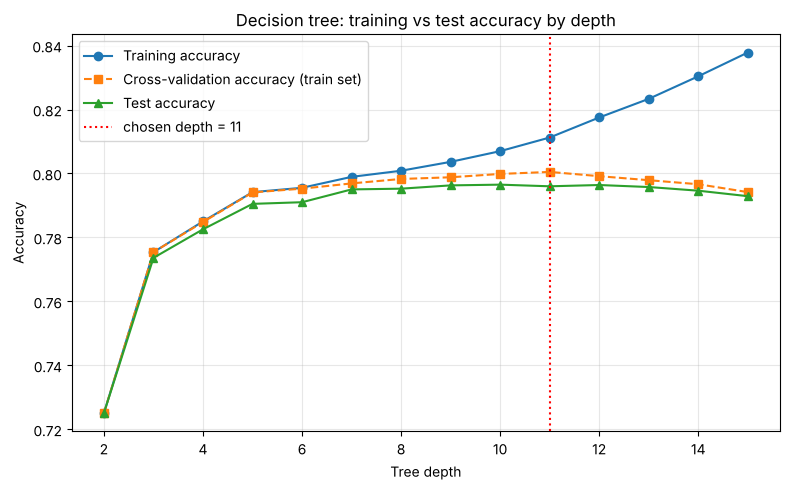

In [3]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for d in range(2, 16):
    m = dt_pipe(features, d).fit(X_train[features], y_train)
    rows.append({"depth":d,
                 "train_acc": accuracy_score(y_train, m.predict(X_train[features])),
                 "test_acc":  accuracy_score(y_test,  m.predict(X_test[features])),
                 "cv_acc":    cross_val_score(dt_pipe(features, d), X_train[features], y_train,
                                              cv=skf5, scoring="accuracy", n_jobs=-1).mean()})
sweep = pd.DataFrame(rows)
best_depth = int(sweep.loc[sweep["cv_acc"].idxmax(), "depth"])
print(sweep.round(4).to_string(index=False))
print("\nBest depth by cross-validation:", best_depth)

plt.figure(figsize=(8,5))
plt.plot(sweep.depth, sweep.train_acc, "o-", label="Training accuracy")
plt.plot(sweep.depth, sweep.cv_acc,    "s--", label="Cross-validation accuracy (train set)")
plt.plot(sweep.depth, sweep.test_acc,  "^-", label="Test accuracy")
plt.axvline(best_depth, color="red", ls=":", label=f"chosen depth = {best_depth}")
plt.xlabel("Tree depth"); plt.ylabel("Accuracy"); plt.title("Decision tree: training vs test accuracy by depth")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("../outputs/figures/dt_depth_sweep.png", dpi=120); plt.show()

**Reading the plot.** Training accuracy keeps climbing as the tree gets deeper (0.725 at depth 2 to 0.838 at depth 15), but test accuracy stops improving at about depth 10 (≈ 0.797) and then drifts down (0.793 at depth 15). The widening gap between the two lines is **overfitting**: deep trees memorise the training bookings instead of learning general patterns. Depth 2 scores 0.725, exactly the baseline, because a tree that shallow predicts "not cancelled" for everyone. Cross-validation (training set only) picks **depth 11**; deeper trees get worse.

This is why a single tree is not our final model, and why the random forest (many trees averaged) is the natural fix.

**A small, readable tree** (depth 3). Each box shows the question asked, how many bookings reached it, and the class split; orange = mostly not cancelled, blue = mostly cancelled.

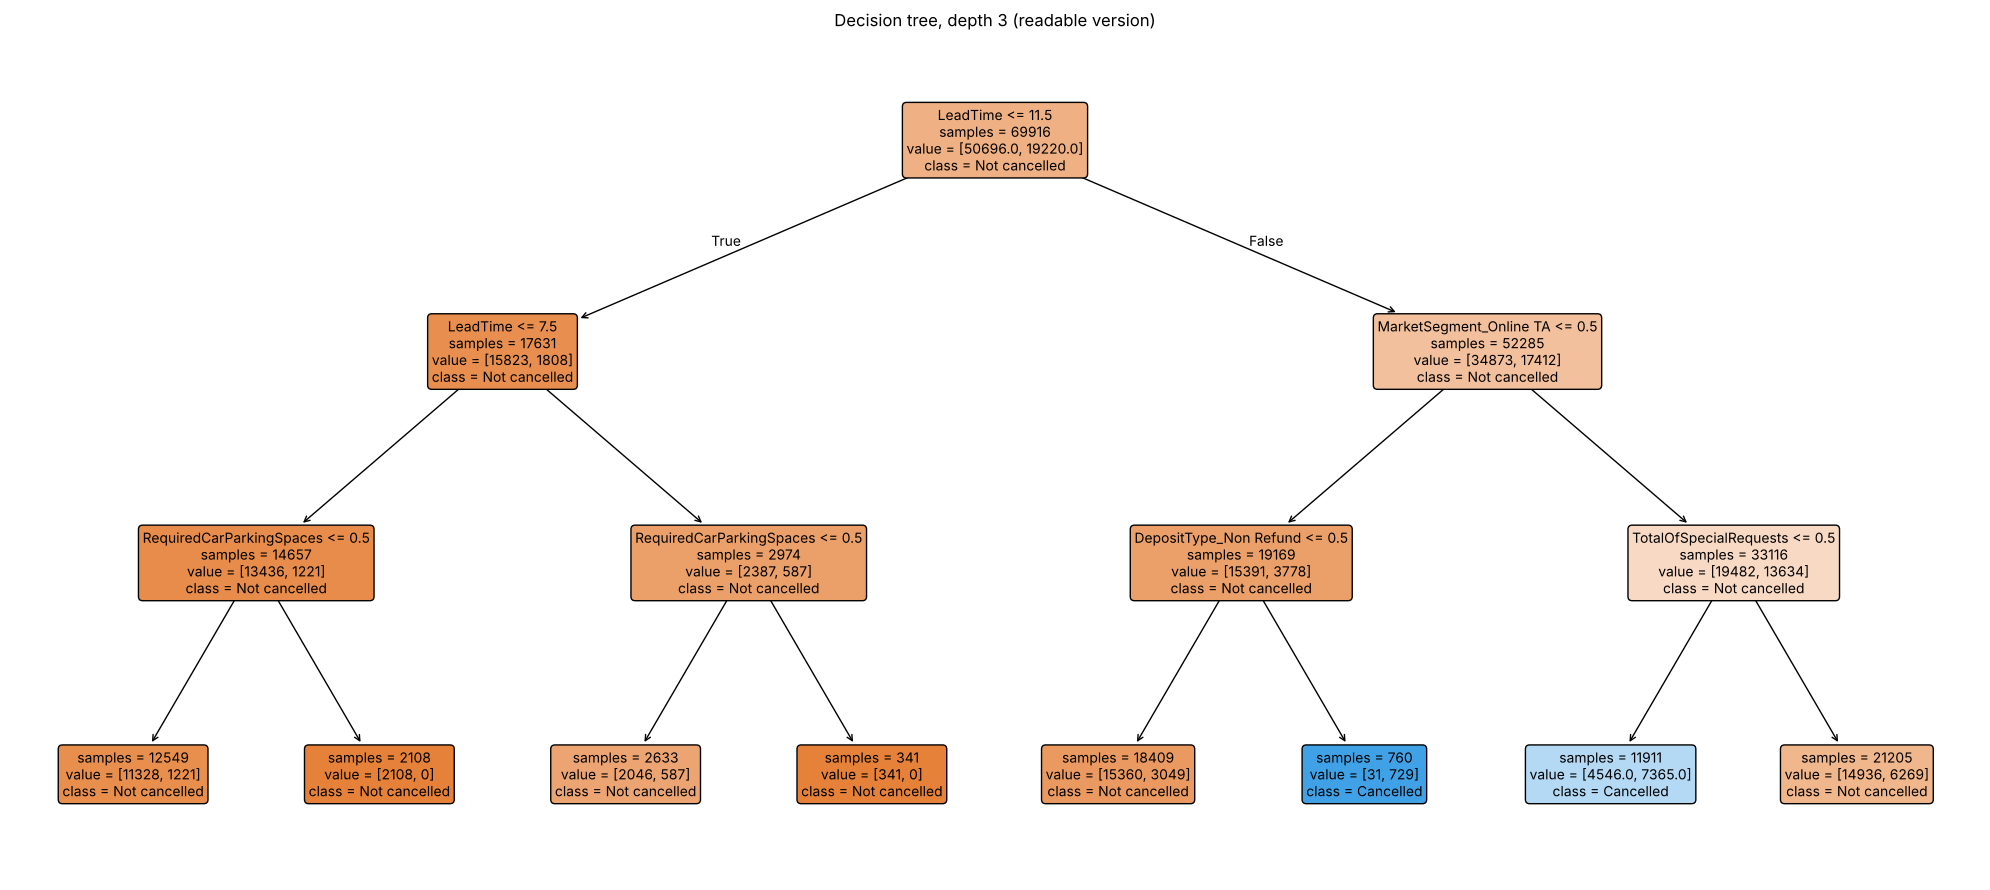

In [4]:
dt3 = dt_pipe(features, 3).fit(X_train[features], y_train)
names = [n.split("__", 1)[1] for n in dt3.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(20, 9))
plot_tree(dt3.named_steps["clf"], feature_names=names, class_names=["Not cancelled","Cancelled"],
          filled=True, rounded=True, fontsize=10, proportion=False, impurity=False)
plt.title("Decision tree, depth 3 (readable version)")
plt.tight_layout(); plt.savefig("../outputs/figures/dt_depth3_tree.png", dpi=110); plt.show()

**What the tree says.** The first question is lead time (≤ 11.5 days): short-notice bookings are mostly kept. For longer lead times the next question is the market segment. **Online TA** bookings with **no special requests** are mostly cancelled (about 62% of the 11,911 bookings in that box), a **non-refundable deposit** box is almost always cancelled (729 of 760), and short-lead bookings with a **parking request** are never cancelled in this data (2,449 bookings). The same story as the logistic odds ratios, but as questions anyone can follow.

## 4. Comparison table (with baseline)

All models use the **main feature set (no Country)** and the same test set.

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train[features], y_train)
main = {
    "Logistic Regression":                    (logit_pipe(features), features),
    f"Decision Tree (depth {best_depth})":     (dt_pipe(features, best_depth), features),
    "Random Forest":                          (rf_pipe(features), features),
    "Gradient Boosting":                      (gb_pipe(features), features),
}
fitted = {}
rows = [score(dummy, features, "Baseline (always 'not cancelled')")]
for name, (pipe, cols) in main.items():
    t = time.time(); pipe.fit(X_train[cols], y_train); fitted[name] = (pipe, cols)
    rows.append(score(pipe, cols, name)); print(f"{name:28s} trained in {time.time()-t:5.1f}s")
comp = pd.DataFrame(rows)
print(); print(comp.round(3).to_string(index=False))

Logistic Regression          trained in   0.8s


Decision Tree (depth 11)     trained in   0.4s


Random Forest                trained in  14.2s


Gradient Boosting            trained in   1.7s

                            Model  Accuracy  Precision  Recall    F1  ROC-AUC
Baseline (always 'not cancelled')     0.725      0.000   0.000 0.000    0.500
              Logistic Regression     0.784      0.690   0.388 0.497    0.794
         Decision Tree (depth 11)     0.796      0.673   0.500 0.574    0.821
                    Random Forest     0.815      0.740   0.505 0.601    0.857
                Gradient Boosting     0.809      0.719   0.504 0.592    0.849


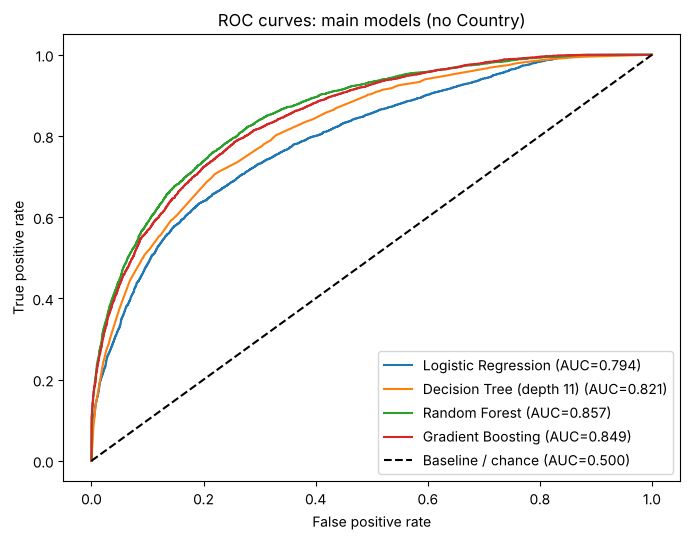

In [6]:
fig, ax = plt.subplots(figsize=(7,5.5))
for name, (pipe, cols) in fitted.items():
    p = pipe.predict_proba(X_test[cols])[:,1]
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
ax.plot([0,1],[0,1],"k--",label="Baseline / chance (AUC=0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves: main models (no Country)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("../outputs/figures/model_roc_comparison.png", dpi=120); plt.show()

**Reading the table.**

- The **baseline** reaches 72.5% accuracy but has recall 0 and AUC 0.50. Every real model beats it.
- **Headline: Gradient Boosting, AUC 0.849 (without Country)**, up from 0.794 for logistic regression.
- The single decision tree (AUC 0.821, depth 11) beats logistic regression but is clearly behind the ensembles.
- Random forest (0.857) and gradient boosting (0.849) are within 0.01 AUC, so we treat them as equivalent. We use gradient boosting for the rest of the notebook because it trains about 8× faster here (1.7 s vs 14.2 s) and is the model we export.
- Accuracy barely moves (0.78 to 0.82) because of the class imbalance; recall and F1 show the real differences.

## 5. Sensitivity: Country, parking and ADR

We re-fit every model with and without the three columns we are unsure about:
- **Country** — the real country is often only known at check-in, so it may be an unfair hint.
- **RequiredCarParkingSpaces** — no booking with a parking request was cancelled, so the field may be filled in late.
- **ADR** — the price is final-recorded, so later adjustments could leak in slightly.

If the headline conclusions hold without them, they do not depend on these columns.

In [7]:
park = "RequiredCarParkingSpaces"
variants = {
    "Main (no Country)":        features,
    "No parking":               [c for c in features if c != park],
    "No ADR":                   [c for c in features if c != "ADR"],
    "+ Country":                features_c,
    "+ Country, no parking":    [c for c in features_c if c != park],
}
builders = {"Logistic Regression": logit_pipe, f"Decision Tree (depth {best_depth})": lambda c: dt_pipe(c, best_depth),
            "Random Forest": rf_pipe, "Gradient Boosting": gb_pipe}
rows = []
for vname, vcols in variants.items():
    for mname, build in builders.items():
        m = build(vcols).fit(X_train[vcols], y_train)
        p = m.predict_proba(X_test[vcols])[:,1]; pred = (p >= 0.5).astype(int)
        rows.append({"Variant":vname, "Model":mname, "ROC-AUC":roc_auc_score(y_test,p),
                     "F1":f1_score(y_test,pred), "Recall":recall_score(y_test,pred)})
sens = pd.DataFrame(rows)
print("ROC-AUC"); print(sens.pivot(index="Model", columns="Variant", values="ROC-AUC")[list(variants)].round(3).to_string())
print("\nF1 (threshold 0.5)"); print(sens.pivot(index="Model", columns="Variant", values="F1")[list(variants)].round(3).to_string())

ROC-AUC
Variant                   Main (no Country)  No parking  No ADR  + Country  + Country, no parking
Model                                                                                            
Decision Tree (depth 11)              0.821       0.801   0.821      0.868                  0.854
Gradient Boosting                     0.849       0.831   0.845      0.900                  0.885
Logistic Regression                   0.794       0.768   0.790      0.834                  0.813
Random Forest                         0.857       0.839   0.850      0.899                  0.884

F1 (threshold 0.5)
Variant                   Main (no Country)  No parking  No ADR  + Country  + Country, no parking
Model                                                                                            
Decision Tree (depth 11)              0.574       0.560   0.578      0.649                  0.634
Gradient Boosting                     0.592       0.577   0.590      0.681                

**Reading the tables.**

- **Country** adds about 0.04 to 0.05 AUC to every model (gradient boosting 0.849 → 0.900). That jump is exactly why it is suspicious: if the real country is only known at check-in, a day-before-arrival model should not lean on it. We report 0.849 as the headline and keep the Country result as a sensitivity check only.
- **Parking:** removing it costs about 0.02 AUC (gradient boosting 0.849 → 0.831). It helps, but the conclusions do not depend on it: every model still beats the baseline by a wide margin and the model ranking is unchanged.
- **ADR:** removing it barely matters (0.849 → 0.845), so ADR is not driving the results.
- In every variant the order is the same: logistic regression < decision tree < gradient boosting ≈ random forest.

## 6. Tune the threshold properly

Choosing a threshold *on the test set* and then reporting test scores is slightly optimistic. Instead we carve a **validation set** out of the training data (`random_state=42`), pick the threshold there, and only then score once on the untouched test set. The model is the headline **Gradient Boosting (no Country)**.

In [8]:
best_name = "Gradient Boosting"
cols = features
X_tr, X_val, y_tr, y_val = train_test_split(X_train[cols], y_train, test_size=0.25, stratify=y_train, random_state=42)

val_model = gb_pipe(cols).fit(X_tr, y_tr)
p_val = val_model.predict_proba(X_val)[:,1]
grid = np.arange(0.10, 0.80, 0.01)
f1s = [f1_score(y_val, (p_val >= t).astype(int)) for t in grid]
best_t = float(grid[int(np.argmax(f1s))])
print(f"Best threshold on validation set: {best_t:.2f}  (F1 = {max(f1s):.3f})")

final_model, _ = fitted[best_name]
p_test = final_model.predict_proba(X_test[cols])[:,1]
for t in [0.5, best_t]:
    pr = (p_test >= t).astype(int)
    print(f"threshold {t:.2f} -> Precision {precision_score(y_test,pr):.3f} | Recall {recall_score(y_test,pr):.3f} | "
          f"F1 {f1_score(y_test,pr):.3f} | Accuracy {accuracy_score(y_test,pr):.3f}")

Best threshold on validation set: 0.31  (F1 = 0.653)
threshold 0.50 -> Precision 0.719 | Recall 0.504 | F1 0.592 | Accuracy 0.809
threshold 0.31 -> Precision 0.582 | Recall 0.718 | F1 0.643 | Accuracy 0.781


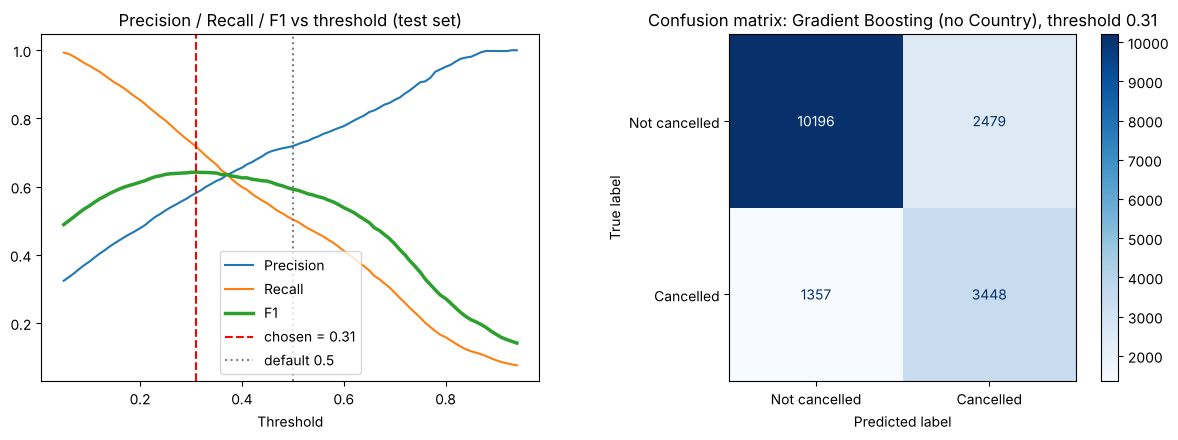

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ts = np.arange(0.05, 0.95, 0.01)
ax[0].plot(ts, [precision_score(y_test,(p_test>=t).astype(int), zero_division=0) for t in ts], label="Precision")
ax[0].plot(ts, [recall_score(y_test,(p_test>=t).astype(int)) for t in ts], label="Recall")
ax[0].plot(ts, [f1_score(y_test,(p_test>=t).astype(int)) for t in ts], label="F1", lw=2.5)
ax[0].axvline(best_t, color="red", ls="--", label=f"chosen = {best_t:.2f}"); ax[0].axvline(0.5, color="grey", ls=":", label="default 0.5")
ax[0].set_xlabel("Threshold"); ax[0].set_title("Precision / Recall / F1 vs threshold (test set)"); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(y_test, (p_test>=best_t).astype(int), display_labels=["Not cancelled","Cancelled"],
                                        cmap="Blues", ax=ax[1], values_format="d")
ax[1].set_title(f"Confusion matrix: {best_name} (no Country), threshold {best_t:.2f}")
plt.tight_layout(); plt.savefig("../outputs/figures/gb_threshold_confusion.png", dpi=120); plt.show()

The threshold is a **business choice**: a higher threshold means fewer false alarms but more missed cancellations. The validation-picked value balances the two (best F1).

For the headline model the validation-chosen threshold is **0.31**: recall rises from 0.50 to 0.72 and F1 from 0.59 to 0.64, at the cost of precision (0.72 → 0.58).

## 7. What drives the best model?

Permutation importance: shuffle one column at a time on the test set and see how much AUC drops. A bigger drop = the model relies on that column more. (Importance does not give direction; for direction see the odds ratios in Notebook 04.)

LeadTime                       0.0949
RequiredCarParkingSpaces       0.0720
TotalOfSpecialRequests         0.0590
MarketSegment                  0.0554
CustomerType                   0.0313
ADR                            0.0304
PreviousCancellations          0.0220
BookingChanges                 0.0140
PreviousBookingsNotCanceled    0.0140
DepositType                    0.0128
ArrivalDateYear                0.0120
Hotel                          0.0112
dtype: float64


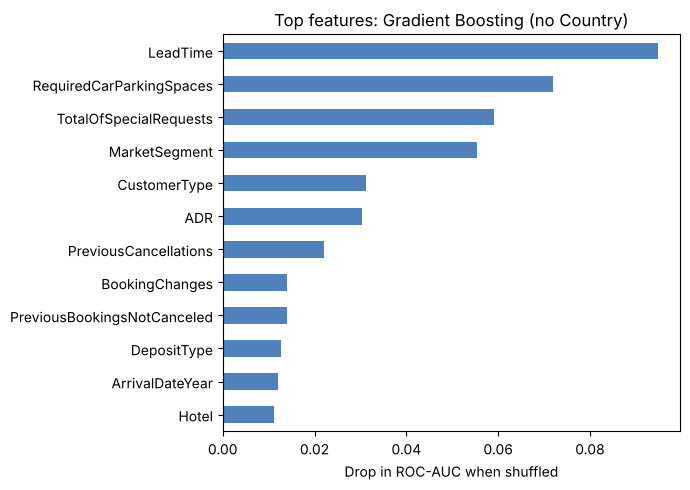

In [10]:
pi = permutation_importance(final_model, X_test[cols], y_test, scoring="roc_auc",
                            n_repeats=3, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=cols).sort_values(ascending=False)
print(imp.head(12).round(4))
imp.head(12).sort_values().plot.barh(color="#4f81bd", figsize=(7,5))
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title("Top features: Gradient Boosting (no Country)")
plt.tight_layout(); plt.savefig("../outputs/figures/gb_feature_importance.png", dpi=120); plt.show()

## 8. Power BI export

> **Note:** this cell still scores with the *Country* model from the earlier version. It is switched to the no-Country model in the next revision (the dashboard must use the no-Country model).

5-fold out-of-fold probabilities, so every booking is scored by a model that did not train on it.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lr = cross_val_predict(logit_pipe(features),  df[features],   y, cv=skf, method="predict_proba")[:,1]
oof_gb = cross_val_predict(gb_pipe(features_c),   df[features_c],  y, cv=skf, method="predict_proba")[:,1]
print("Out-of-fold ROC-AUC  LR:", round(roc_auc_score(y, oof_lr),3), "| GB+Country:", round(roc_auc_score(y, oof_gb),3))

out = df.copy()
out["PredCancelProb_LR"] = oof_lr.round(4)
out["PredCancelProb"]    = oof_gb.round(4)                      # best model
out["PredCancelled"]     = (oof_gb >= best_t).astype(int)
out["RiskBand"] = pd.cut(oof_gb, [-0.01, 0.2, 0.5, 1.0], labels=["Low","Medium","High"])
out["Outcome"] = np.select(
    [(out.IsCanceled==1)&(out.PredCancelled==1), (out.IsCanceled==0)&(out.PredCancelled==0), (out.IsCanceled==0)&(out.PredCancelled==1)],
    ["True Positive","True Negative","False Positive"], default="False Negative")
print(out.groupby("RiskBand", observed=True)["IsCanceled"].agg(["count","mean"]).round(3))
out.to_csv("../outputs/hotel_bookings_powerbi.csv", index=False)
comp.to_csv("../outputs/model_comparison_all.csv", index=False)
sens.to_csv("../outputs/model_sensitivity.csv", index=False)

Out-of-fold ROC-AUC  LR: 0.799 | GB+Country: 0.902
          count   mean
RiskBand              
Low       47807  0.050
Medium    18892  0.335
High      20697  0.740
